# EE 513 Assignment 3 

**Name:** Andrei Perez **Camera:** iPhone 17 Pro Max, 6.765 mm f/1.78, raw DNG, ISO 64, Adobe Lightroom


# Setup

In [22]:
import json, struct, sys
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
import rawpy

plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})

ROOT    = Path.cwd()                              
FLAT_DIR = ROOT / "flat_field_pairs"
DARK_DIR = ROOT / "dark_field"
A1_DIR, A2_DIR = ROOT.parent / "A1", ROOT.parent / "A2"
OUT_DIR = ROOT / "outputs"; OUT_DIR.mkdir(exist_ok=True)

sys.path.insert(0, str(A2_DIR))
import psu_imaging as psu

flat_files = sorted(FLAT_DIR.glob("*.dng"))
dark_files = sorted(DARK_DIR.glob("*.dng"))

In [23]:
# Resuing from A2

_TYPES = {1: ("B", 1), 2: ("s", 1), 3: ("H", 2), 4: ("I", 4), 5: ("II", 8), 7: ("B", 1),
          8: ("h", 2), 9: ("i", 4), 10: ("ii", 8), 11: ("f", 4), 12: ("d", 8)}
_TAGS = {0x010F: "make", 0x0110: "model", 0xC761: "noise_profile",          
         0x829A: "exposure_s", 0x829D: "N", 0x8827: "iso",                 
         0x920A: "f_mm", 0xA434: "lens_model"}


def _read_ifd(fh, offset, endian):
    fh.seek(offset)
    (count,) = struct.unpack(endian + "H", fh.read(2))
    entries = [struct.unpack(endian + "HHII", fh.read(12)) for _ in range(count)]
    out = {}
    for tag, typ, n, value_or_offset in entries:
        if typ not in _TYPES:
            continue
        code, size = _TYPES[typ]
        nbytes = size * n
        if nbytes <= 4:
            raw = struct.pack(endian + "I", value_or_offset)[:nbytes]
        else:
            here = fh.tell(); fh.seek(value_or_offset); raw = fh.read(nbytes); fh.seek(here)
        if typ == 2:
            val = raw.split(b"\x00", 1)[0].decode(errors="replace").strip()
        elif typ in (5, 10):
            nums = struct.unpack(endian + code[0] * (2 * n), raw)
            vals = [a / b if b else float("nan") for a, b in zip(nums[0::2], nums[1::2])]
            val = vals[0] if n == 1 else tuple(vals)
        else:
            vals = struct.unpack(endian + code * n, raw)
            val = vals[0] if n == 1 else vals
        out[tag] = val
    return out


def read_exif(path):
    # Metadata extraction
    with open(path, "rb") as fh:
        endian = {b"II": "<", b"MM": ">"}[fh.read(2)]
        _, ifd0 = struct.unpack(endian + "HI", fh.read(6))
        tags = _read_ifd(fh, ifd0, endian)
        if 0x8769 in tags:
            tags.update(_read_ifd(fh, tags[0x8769], endian))
    e = {name: tags.get(tag) for tag, name in _TAGS.items()}
    e["file"] = Path(path).name
    return e


def green_plane(path, which=0):
    # geen plane interp
    with rawpy.imread(str(path)) as raw:
        bayer = raw.raw_image_visible.astype(np.float64)
        pattern, desc = raw.raw_pattern, raw.color_desc.decode()
        blacks, white = raw.black_level_per_channel, float(raw.white_level)
    greens = [(r, c) for r in range(2) for c in range(2) if desc[pattern[r, c]] == "G"]
    r0, c0 = greens[which]
    return bayer[r0::2, c0::2], {"site": (r0, c0), "black": float(blacks[pattern[r0, c0]]), "white": white}


def center_patch(plane, size=128):
    h, w = plane.shape
    return plane[h // 2 - size // 2: h // 2 + size // 2, w // 2 - size // 2: w // 2 + size // 2]


def lens_id(path):
    e = read_exif(path)
    return (e["make"], e["model"], e["lens_model"], round(e["f_mm"], 3), round(e["N"], 2))

# Part 1 Captures

## Item 1 · Flat-field pairs

Capture at least ten pairs of flat fields spanning the range from nearly black to nearly saturated, two frames at each level with nothing moved or changed between them.

In [34]:
meta = [read_exif(f) for f in flat_files + dark_files]
print(f"{'file':20s} {'exposure (s)':>12s} {'ISO':>5s}")
for e in meta:
    print(f"{e['file']:20s} {e['exposure_s']:12.4f} {e['iso']:5.0f}")

pairs = list(zip(flat_files[0::2], flat_files[1::2]))
BLACK = green_plane(flat_files[0])[1]["black"]; WHITE = green_plane(flat_files[0])[1]["white"]
print(f"\n{len(pairs)} pairs; black level {BLACK:.0f} DN, white level {WHITE:.0f} DN")
for a, b in pairs:
    ma, mb = center_patch(green_plane(a)[0]).mean(), center_patch(green_plane(b)[0]).mean()
    print(f"  {a.name} / {b.name}: mean {ma:7.1f} / {mb:7.1f} DN")

file                 exposure (s)   ISO
flat_field001.dng          0.1250    64
flat_field002.dng          0.1250    64
flat_field003.dng          0.1250    64
flat_field004.dng          0.1250    64
flat_field005.dng          0.1250    64
flat_field006.dng          0.1250    64
flat_field007.dng          0.1250    64
flat_field008.dng          0.1250    64
flat_field009.dng          0.1250    64
flat_field010.dng          0.1250    64
flat_field011.dng          0.1250    64
flat_field012.dng          0.1250    64
flat_field013.dng          0.1250    64
flat_field014.dng          0.1250    64
flat_field015.dng          0.1250    64
flat_field016.dng          0.1250    64
flat_field017.dng          0.1250    64
flat_field018.dng          0.1250    64
flat_field019.dng          0.1250    64
flat_field020.dng          0.1250    64
dark_field001.dng          1.0000    64
dark_field002.dng          0.0020    64
dark_field003.dng          0.0400    64
dark_field004.dng          1.0000    64


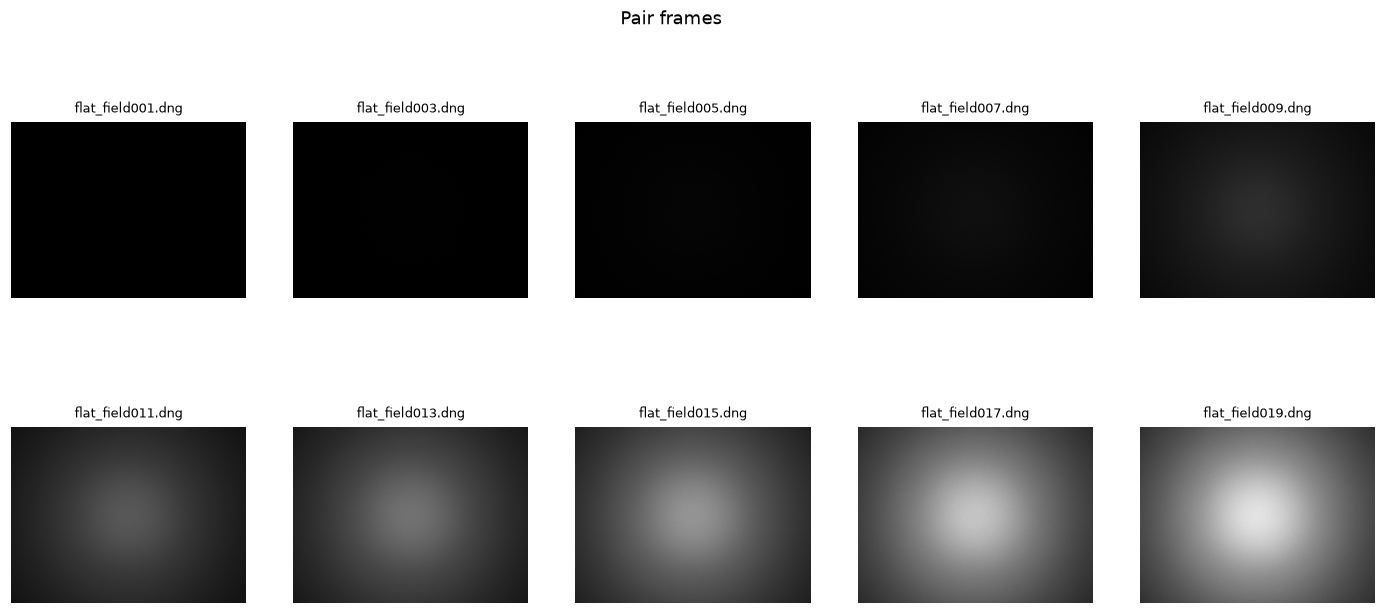

In [30]:
fig, axes = plt.subplots(2, 5, figsize=(16, 6.6))
for ax, (a, _) in zip(axes.ravel(), pairs):
    g, info = green_plane(a)
    ax.imshow(g[::4, ::4], cmap="gray", vmin=info["black"], vmax=info["white"]) 
    ax.set_title(f"{a.name}", fontsize=8.5)
    ax.axis("off")
fig.suptitle("Pair frames")
fig.savefig(OUT_DIR / "item01_contact_sheet.png", bbox_inches="tight"); plt.show()

## Item 2 Same ISO

In [36]:
all_files = flat_files + dark_files
keys = {f.name: (lens_id(f), read_exif(f)["iso"]) for f in all_files}
distinct = set(keys.values())
for k in distinct:
    print(k)
assert len(distinct) == 1, f"More than one camera/ISO in the series: {distinct}"
print(f"All {len(all_files)} captures share same lens_id and ISO {read_exif(all_files[0])['iso']:.0f}")

(('Apple', 'iPhone 17 Pro Max', 'iPhone 17 Pro Max back camera 6.765mm f/1.78', 6.765, 1.8), 64)
All 24 captures share same lens_id and ISO 64


## Item 3 Dark Frames

Capture five dark frames with the lens covered at each of four exposure times, spanning the longest range your app allows, and compare their level against the black level recorded in the file.

In [37]:
def cfa_means(path, patch=None):
    with rawpy.imread(str(path)) as raw:
        b = raw.raw_image_visible.astype(float); pat, desc = raw.raw_pattern, raw.color_desc.decode()
        blacks = raw.black_level_per_channel
    out = {}
    for r in range(2):
        for c in range(2):
            plane = b[r::2, c::2]
            if patch: plane = center_patch(plane, patch)
            out[f"{desc[pat[r, c]]}({r},{c})"] = (plane.mean(), np.median(plane), blacks[pat[r, c]])
    return out

dark_exp = np.array([read_exif(f)["exposure_s"] for f in dark_files])
shortest = dark_files[int(np.argmin(dark_exp))]
print(f"Shortest dark frame: {shortest.name}, {dark_exp.min() * 1000:.0f} ms\n")
print(f"{'CFA site':10s} {'file black (DN)':>16s} {'dark mean (DN)':>15s} {'dark median':>12s}")
for k, (m, med, bl) in cfa_means(shortest).items():
    print(f"{k:10s} {bl:16.0f} {m:15.2f} {med:12.1f}")

Shortest dark frame: dark_field002.dng, 2 ms

CFA site    file black (DN)  dark mean (DN)  dark median
B(0,0)                  528          527.69        528.0
G(0,1)                  528          527.54        528.0
G(1,0)                  528          527.54        528.0
R(1,1)                  528          527.70        528.0


> **Answer**
>
> **528 DN for all four CFA channels** (B, G, G, R). **Shortest dark frame means were B 527.69, G 527.54, G 527.54, R 527.70 DN** The two agree.
> I noticed by these readings that the largest and shortes exposures on the app show the same here. I will consider this for the project.

# Part 2 · The Photon Transfer Curve

In [38]:
def ptc_points(frame_pairs, black):
    m, vp, vs = [], [], []
    for a, b in frame_pairs:
        m.append((a.mean() + b.mean()) / 2 - black)
        vp.append(np.var(a - b) / 2)
        vs.append(a.var())
    return np.array(m), np.array(vp), np.array(vs)


def fit_ptc(mean, var, full_scale, frac=0.70, n_pix=128 * 128):
    ok = mean < frac * full_scale
    sig = np.maximum(var[ok], 1e-6) * np.sqrt(2 / (n_pix - 1))
    (K, c), cov = np.polyfit(mean[ok], var[ok], 1, w=1 / sig, cov=True)
    dK, dc = np.sqrt(np.diag(cov))
    read = np.sqrt(max(c, 0)) / K
    J = np.array([-np.sqrt(max(c, 0)) / K**2, 1 / (2 * np.sqrt(max(c, 1e-12)) * K)])
    dread = float(np.sqrt(J @ cov @ J))
    return dict(K=K, dK=dK, c=c, dc=dc, read=read, dread=dread, used=ok)

## Item 4 Validate with simulated sensor

Before fitting any of your own data, run your photon transfer code on the simulated sensor in the lecture 5 demo notebook, which reports the true gain and read noise it used to generate the frames.

In [39]:
TRUE_K, TRUE_READ = (psu.WHITE_LEVEL - psu.BLACK_LEVEL) / psu.FULL_WELL, psu.READ_NOISE
PRNU = 0.012
def sim_pair(electrons, i):
    patch = np.full((128, 128), electrons / psu.FULL_WELL)
    a = psu.expose_and_digitize(patch, np.random.default_rng(2 * i), prnu=PRNU).astype(float)
    b = psu.expose_and_digitize(patch, np.random.default_rng(2 * i + 1), prnu=PRNU).astype(float)
    return a, b

levels = np.logspace(np.log10(5), np.log10(psu.FULL_WELL * 0.92), 22)
sm, svp, svs = ptc_points([sim_pair(e, i) for i, e in enumerate(levels)], psu.BLACK_LEVEL)
sim = fit_ptc(sm, svp, psu.WHITE_LEVEL - psu.BLACK_LEVEL)

print(f"{'':16s}{'recovered':>20s}{'true':>10s}{'error':>9s}")
print(f"{'gain K (DN/e-)':16s}{sim['K']:12.4f} ± {sim['dK']:.4f}{TRUE_K:10.4f}{100 * (sim['K'] - TRUE_K) / TRUE_K:+8.2f} %")
print(f"{'read noise (e-)':16s}{sim['read']:12.3f} ± {sim['dread']:.3f}{TRUE_READ:10.3f}{100 * (sim['read'] - TRUE_READ) / TRUE_READ:+8.2f} %")

                           recovered      true    error
gain K (DN/e-)        0.4233 ± 0.0011    0.4266   -0.77 %
read noise (e-)        2.944 ± 0.018     2.800   +5.16 %


## Item 5 Mean and variance of each pair

For each pair, compute the mean signal as the average of the two frame means with the black level subtracted, and the variance as half the variance of the difference of the two frames.

In [43]:
FULL_SCALE = WHITE - BLACK
patches = [(center_patch(green_plane(a)[0]), center_patch(green_plane(b)[0])) for a, b in pairs]
N_PIX = patches[0][0].size
mean, var_pair, var_single = ptc_points(patches, BLACK)

print(f"Patch: {N_PIX} pixels of the green plane G(0,1)\n")
print(f"{'pair':>4s} {'files':24s} {'DN (mean)':>14s} {'DN² (variance)':>10s} {'% of sat.':>9s}")
for i, ((a, b), m, v) in enumerate(zip(pairs, mean, var_pair)):
    print(f"{i + 1:4d} {a.stem[-3:] + '/' + b.stem[-3:]:24s} {m:14.2f} {v:10.2f} {100 * m / FULL_SCALE:9.1f}")

Patch: 16384 pixels of the green plane G(0,1)

pair files                         DN (mean) DN² (variance) % of sat.
   1 001/002                            0.62       3.65       0.0
   2 003/004                           28.41      10.41       0.8
   3 005/006                           82.35      23.60       2.3
   4 007/008                          226.90      58.44       6.4
   5 009/010                          642.17     169.74      18.0
   6 011/012                         1224.19     367.95      34.3
   7 013/014                         1581.02     465.59      44.3
   8 015/016                         2061.42     727.79      57.8
   9 017/018                         2726.13     878.99      76.4
  10 019/020                         3147.90    1033.11      88.3


## Item 6 · Fit below 70 % of saturation

Fit a line through the points that lie below 70 percent of saturation, and report the conversion gain and the read noise.
Deliverable: A figure of variance against mean showing the fitted line with the excluded points distinguished, the gain in digital numbers per electron, and the read noise in electrons, each with an uncertainty from the fit.

Below 0.7 we found 8 of 10
Conversion gain  K   = 0.2727 ± 0.0142 DN/e-   (3.667 e-/DN)
Read noise 6.68 ± 0.61 e- 


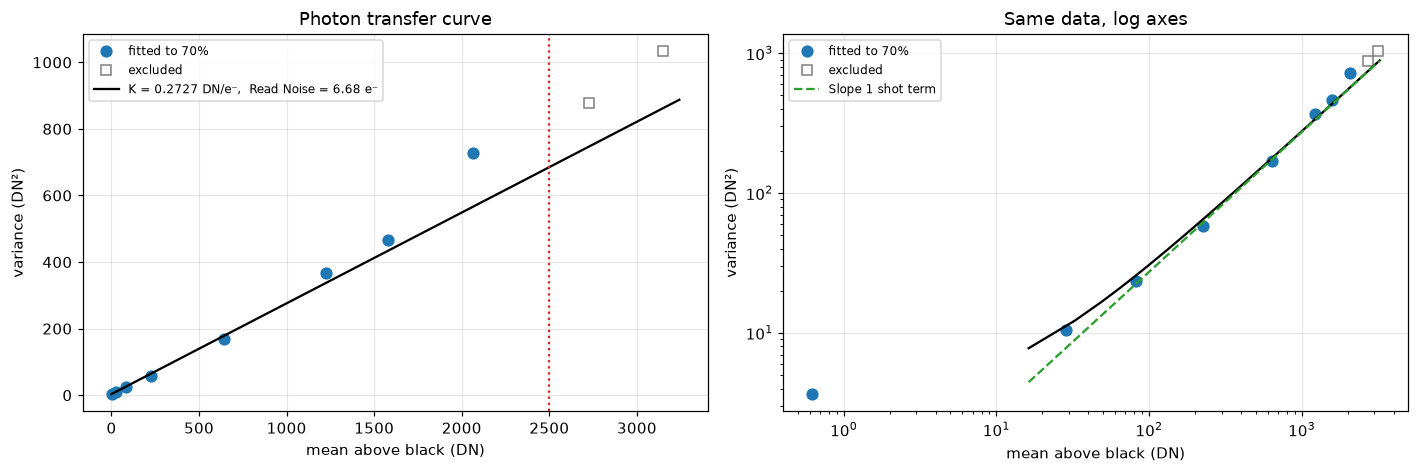

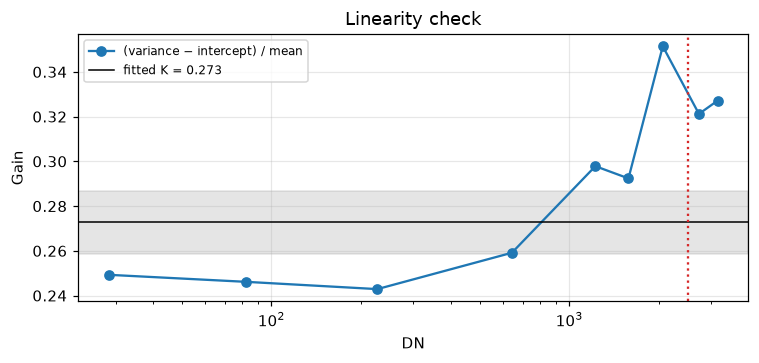

Apparent gain per pair: [0.249, 0.246, 0.243, 0.259, 0.298, 0.292, 0.351, 0.321, 0.327]


In [53]:
fit = fit_ptc(mean, var_pair, FULL_SCALE)
K, dK, READ, dREAD = fit["K"], fit["dK"], fit["read"], fit["dread"]
used = fit["used"]
print(f"Below 0.7 we found {used.sum()} of {len(used)}")
print(f"Conversion gain  K   = {K:.4f} ± {dK:.4f} DN/e-   ({1 / K:.3f} e-/DN)")
print(f"Read noise {READ:.2f} ± {dREAD:.2f} e- ")

xs = np.linspace(0, mean.max() * 1.03, 200)
fig, axes = plt.subplots(1, 2, figsize=(13, 4.4))
for ax in axes:
    ax.plot(mean[used], var_pair[used], "o", ms=7, label="fitted to 70%")
    ax.plot(mean[~used], var_pair[~used], "s", ms=7, mfc="none", c="gray", label="excluded")
ax = axes[0]
ax.plot(xs, K * xs + fit["c"], "k-", lw=1.5, label=f"K = {K:.4f} DN/e⁻,  Read Noise = {READ:.2f} e⁻")
ax.axvline(0.7 * FULL_SCALE, ls=":", c="tab:red")
ax.set(xlabel="mean above black (DN)", ylabel="variance (DN²)", title="Photon transfer curve"); ax.legend(fontsize=8)
ax = axes[1]
ax.loglog(xs[1:], K * xs[1:] + fit["c"], "k-", lw=1.5)
ax.loglog(xs[1:], K * xs[1:], "--", c="tab:green", label="Slope 1 shot term")
ax.set(xlabel="mean above black (DN)", ylabel="variance (DN²)", title="Same data, log axes"); ax.legend(fontsize=8)
fig.tight_layout(); fig.savefig(OUT_DIR / "item06_ptc.png", bbox_inches="tight"); plt.show()

k_local = (var_pair - fit["c"]) / np.maximum(mean, 1e-9)
fig, ax = plt.subplots(figsize=(7, 3.4))
ax.semilogx(mean[1:], k_local[1:], "o-", label="(variance − intercept) / mean")
ax.axhline(K, c="k", lw=1, label=f"fitted K = {K:.3f}")
ax.axhspan(K - dK, K + dK, color="gray", alpha=0.2)
ax.axvline(0.7 * FULL_SCALE, ls=":", c="tab:red")
ax.set(xlabel="DN", ylabel="Gain", title="Linearity check")
ax.legend(fontsize=8); fig.tight_layout(); plt.show()
print("Apparent gain per pair:", np.round(k_local[1:], 3).tolist())

> **Answer — item 6**
>
> **$K$ = 0.273 ± 0.014 DN/e⁻** and **read noise = 6.7 ± 0.6 e⁻**, for $N$ = 16,384 pixels.

## Item 7 Single-frame variance fit

Repeat the fit using the variance of a single frame at each level in place of the difference of pairs, and report both gains. The two disagree because one quantity present in the photographs is absent from the model. Name that quantity, and say which way it moves the gain and why.

Pair difference gain K = 0.2727 ± 0.0142 DN/e-
Single-frame gain K = 0.2977 ± 0.0239 DN/e-
Difference           : +9.1 %

0.64 % rms


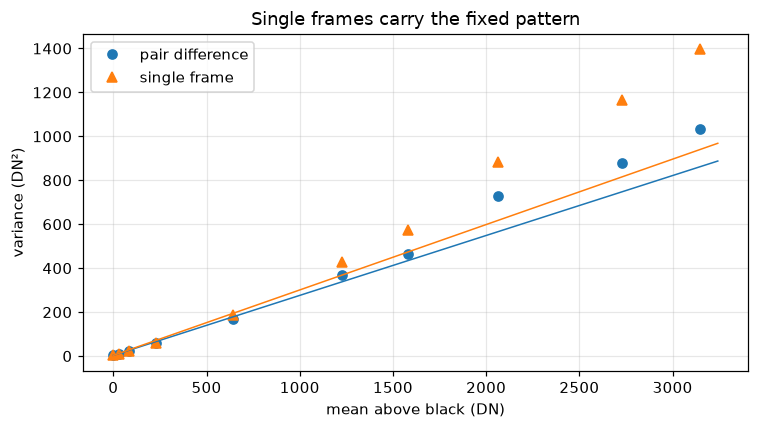

In [56]:
fit_s = fit_ptc(mean, var_single, FULL_SCALE)
print(f"Pair difference gain K = {K:.4f} ± {dK:.4f} DN/e-")
print(f"Single-frame gain K = {fit_s['K']:.4f} ± {fit_s['dK']:.4f} DN/e-")
print(f"Difference           : {100 * (fit_s['K'] - K) / K:+.1f} %")

extra = var_single - var_pair
ok = mean > 50
prnu_est = np.sqrt(np.median(extra[ok & used] / mean[ok & used] ** 2))
#PRNU est
print(f"\n{100 * prnu_est:.2f} % rms")

fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(mean, var_pair, "o", label="pair difference")
ax.plot(mean, var_single, "^", label="single frame")
ax.plot(xs, K * xs + fit["c"], "-", c="tab:blue", lw=1)
ax.plot(xs, fit_s["K"] * xs + fit_s["c"], "-", c="tab:orange", lw=1)
ax.set(xlabel="mean above black (DN)", ylabel="variance (DN²)", title="Single frames carry the fixed pattern"); ax.legend()
fig.tight_layout(); fig.savefig(OUT_DIR / "item07_single_vs_pair.png", bbox_inches="tight"); plt.show()

> **Answer**
>
> **Pair-difference gain 0.273 DN/e⁻; single-frame gain 0.298 DN/e⁻; difference +9.1 %.** This happens because single photos include fixed pattern noise from the research I have done. As the image gets brighter, this fixed noise skews the math, making the sensor look more efficient than it actually is. The pair difference is more accurate since it cancels out the hardware imperfections and reveal the true measurement

## Item 8 Full well and dynamic range

Report your full well capacity in electrons and your dynamic range in stops. More than one convention exists for the low end of the dynamic range, and the number you get depends on which you adopt, so state yours.

In [58]:
FULL_WELL = FULL_SCALE / K
dFW = FULL_WELL * dK / K
mu_snr1 = (1 + np.sqrt(1 + 4 * READ**2)) / 2   
DR_read = np.log2(FULL_WELL / READ)
DR_snr1 = np.log2(FULL_WELL / mu_snr1)
print(f"Full well  {FULL_WELL:,.0f} ± {dFW:,.0f} e-")
print(f"Dynamic range, low end = read noise     {DR_read:.2f} stops   ({FULL_WELL / READ:,.0f} : 1)")
print(f"Dynamic range, low end = SNR 1   {DR_snr1:.2f} stops   (μ = {mu_snr1:.2f} e-)")

Full well  13,079 ± 680 e-
Dynamic range, low end = read noise     10.93 stops   (1,956 : 1)
Dynamic range, low end = SNR 1   10.83 stops   (μ = 7.20 e-)


> **Criterion**
> The low end is the read noise floor. Taking the low end as the signal where SNR = 1 exactly ($\mu$ = 7.2 e⁻) gives 10.8 stops.

<a id="part3"></a>
# Part 3 · Signal to Noise

## Item 9 SNR vs the model

Plot your measured signal-to-noise ratio against signal in electrons on logarithmic axes, draw the curve predicted by your fitted gain and read noise over it, and mark the knee

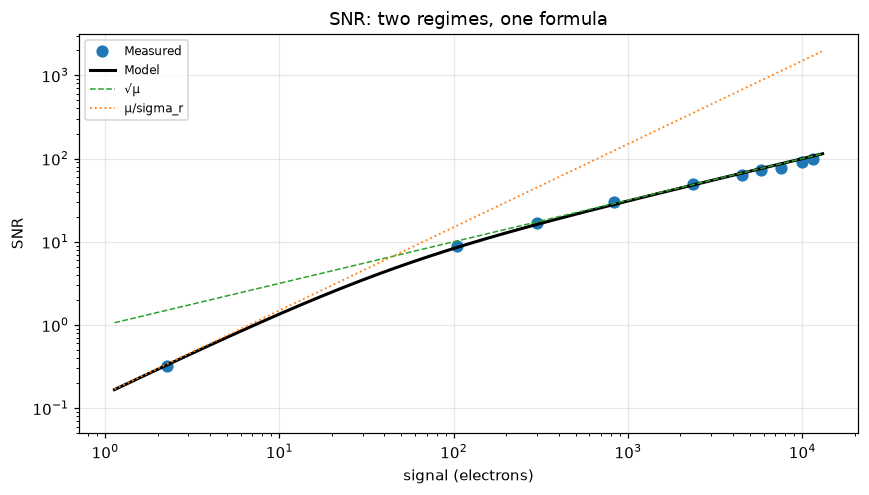

Knee at μ = sigma_r² = 44.7 e-  (12.2 DN above black)
Pairs below knee =  1 
Pairs above knee = 9


In [63]:
pos = mean > 0
e_sig = mean[pos] / K
snr_meas = mean[pos] / np.sqrt(var_pair[pos])
KNEE = READ**2
e_ax = np.logspace(np.log10(max(e_sig.min() * 0.5, 0.1)), np.log10(FULL_WELL), 300)

fig, ax = plt.subplots(figsize=(8, 4.6))
ax.loglog(e_sig, snr_meas, "o", ms=7, label="Measured")
ax.loglog(e_ax, e_ax / np.sqrt(e_ax + READ**2), "k-", lw=2, label=f"Model")
ax.loglog(e_ax, np.sqrt(e_ax), "--", c="tab:green", lw=1, label="√μ")
ax.loglog(e_ax, e_ax / READ, ":", c="tab:orange", lw=1.2, label="μ/sigma_r")
#ax.axvline(KNEE, c="gray", lw=1); ax.text(KNEE * 1.15, 0.12, f"knee {KNEE:.0f} e⁻", color="gray")
ax.set(xlabel="signal (electrons)", ylabel="SNR", ylim=(0.05, None), title="SNR: two regimes, one formula"); ax.legend(fontsize=8)
fig.tight_layout(); fig.savefig(OUT_DIR / "item09_snr.png", bbox_inches="tight"); plt.show()

print(f"Knee at μ = sigma_r² = {KNEE:.1f} e-  ({KNEE * K:.1f} DN above black)")
print(f"Pairs below knee =  {(e_sig < KNEE).sum()} ")
print(f"Pairs above knee = {(e_sig >= KNEE).sum()}")

> **Answer**
>
> **Knee found  = 45 e⁻** or 12 DN above black. The captures barely reach into both regimes.

## Item 10 · The vendor NoiseProfile

Check whether your DNG carries a NoiseProfile tag, which is the manufacturer's own noise model. If it is present, convert it into a gain and a read noise that can be compared against yours; the tag is written in units of normalized signal, so the conversion is a matter of carrying the white level minus the black level through the model.

In [66]:
np_tag = read_exif(flat_files[0])["noise_profile"]
if np_tag is None:
    print("NoiseProfile tag absent")
else:
    S, O = np_tag[:2]
    K_v = S * FULL_SCALE
    read_v = np.sqrt(O) / S
    print(f"NoiseProfile (S, O) = ({S:.4e}, {O:.4e})   [identical in all {len(all_files)} files: "
          f"{len({read_exif(f)['noise_profile'] for f in all_files}) == 1}]\n")
    print(f"{'':20s}{'vendor':>12s}{'measured':>20s}")
    print(f"{'gain K (DN/e-)':20s}{K_v:12.4f}{K:12.4f} ± {dK:.4f}")
    print(f"{'read noise (e-)':20s}{read_v:12.2f}{READ:12.2f} ± {dREAD:.2f}")
    print(f"{'intercept (DN²)':20s}{O * FULL_SCALE**2:12.2f}{fit['c']:12.2f} ± {fit['dc']:.2f}")

NoiseProfile (S, O) = (8.8581e-05, 9.8742e-07)   [identical in all 24 files: True]

                          vendor            measured
gain K (DN/e-)            0.3160      0.2727 ± 0.0142
read noise (e-)            11.22        6.68 ± 0.61
intercept (DN²)            12.56        3.32 ± 0.43


> **Answer**
> Tag matches my gain at high signal, so Apple's profile appears to be fitted to the brighter part of the curve. Something interesting I noticed is that the vendor intercept is about four times the variance actually measured in a 2 ms dark frame, so the vendor read noise looks conservative, maybe tuned for the denoiser rather than describing the sensor.

# Part 4 Dark Current

## Item 11 · Dark current

Fit the dark current from the capped frames you took in item 3 by plotting their mean against exposure time and converting the slope to electrons per second with your gain. Dark current roughly doubles for every 6 to 8 degrees Celsius, so note whether the phone was warm. If your longest available exposure is only a fraction of a second, the result may be indistinguishable from zero, and in that case an upper bound with an argument behind it is the correct answer.

  t (s)   mean−B  median−B  patch−B
  0.002   -0.462      0.00   -0.435
  0.040   -0.371      0.00   -0.318
  1.000    1.837      2.00    3.340
  1.000    1.823      2.00    3.322

Slope of frame mean2.295 ± 0.007 DN/s  resulting in dark current 8.4 ± 0.4 e-/s per pixel
Intercept at -0.46 DN 


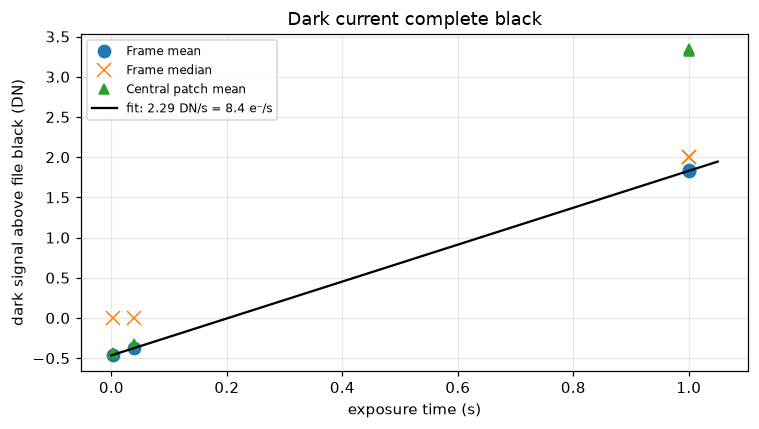

In [71]:
rows = []
for f, t in zip(dark_files, dark_exp):
    g = green_plane(f)[0]
    rows.append((t, g.mean() - BLACK, np.median(g) - BLACK, center_patch(g).mean() - BLACK,
                 g.std() / np.sqrt(g.size), (g > BLACK + 50).mean() * 100))
rows = np.array(rows)
t, d_mean, d_med, d_patch, d_sem, hot = rows.T
order = np.argsort(t)
print(f"{'t (s)':>7s} {'mean−B':>8s} {'median−B':>9s} {'patch−B':>8s}")
for i in order:
    print(f"{t[i]:7.3f} {d_mean[i]:8.3f} {d_med[i]:9.2f} {d_patch[i]:8.3f}")

(slope, icpt), cov = np.polyfit(t, d_mean, 1, cov=True)
dslope = np.sqrt(cov[0, 0])
DARK_E = slope / K
dDARK_E = DARK_E * np.sqrt((dslope / slope) ** 2 + (dK / K) ** 2)
print(f"\nSlope of frame mean{slope:.3f} ± {dslope:.3f} DN/s  resulting in dark current {DARK_E:.1f} ± {dDARK_E:.1f} e-/s per pixel")
print(f"Intercept at {icpt:.2f} DN ")

tt = np.linspace(0, t.max() * 1.05, 50)
fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(t, d_mean, "o", ms=8, label="Frame mean")
ax.plot(t, d_med, "x", ms=9, label="Frame median")
ax.plot(t, d_patch, "^", ms=7, label="Central patch mean")
ax.plot(tt, slope * tt + icpt, "k-", label=f"fit: {slope:.2f} DN/s = {DARK_E:.1f} e⁻/s")
ax.set(xlabel="exposure time (s)", ylabel="dark signal above file black (DN)", title="Dark current complete black"); ax.legend(fontsize=8)
fig.tight_layout(); plt.show()

> **Answer**
>
> **Dark current ≈ 8.4 ± 0.4 e⁻/s per pixel**
> **Phone was at room temperature, not sure how to measure that from sensor**.

# Part 5 Linear Light

## Item 12 encoded values vs averaging light

Construct a checkerboard of pure black and pure white pixels, exactly half of each, and compute its mean twice: once by averaging the sRGB-encoded values directly, and once by linearizing, averaging, and re-encoding.

In [73]:
n = 256
yy, xx = np.mgrid[0:n, 0:n]
checker = ((xx + yy) % 2).astype(float)   
mean_encoded = checker.mean()
mean_linear  = float(psu.linear_to_srgb(psu.srgb_to_linear(checker).mean()))
print(f"Fraction white =  {checker.mean():.3f}")
print(f"Average of the sRGB-encoded values {mean_encoded:.3f}  ({mean_encoded * 255:.0f}/255)")
print(f"If we linearise, then average, then re-encode {mean_linear:.3f}  ({mean_linear * 255:.0f}/255)")

Fraction white =  0.500
Average of the sRGB-encoded values 0.500  (128/255)
If we linearise, then average, then re-encode 0.735  (188/255)


> **Answer**
>
> Camera pointed at a checkerboard records half the light, which is the 0.735 in sRGB. The 0.500 is the arithmetic error.

## Item 13 Encoded values vs averaging light on real data

Do the same thing to real data. Take one of your checkerboard calibration captures from Exercise 1, extract a green plane, encode it to sRGB, and then reduce it by a factor of eight two ways: by averaging the encoded values, and by averaging in linear light and encoding afterward.


Mean difference = 0.55
Pixels with absdiff > 2 levels found in 3.0 % of the image


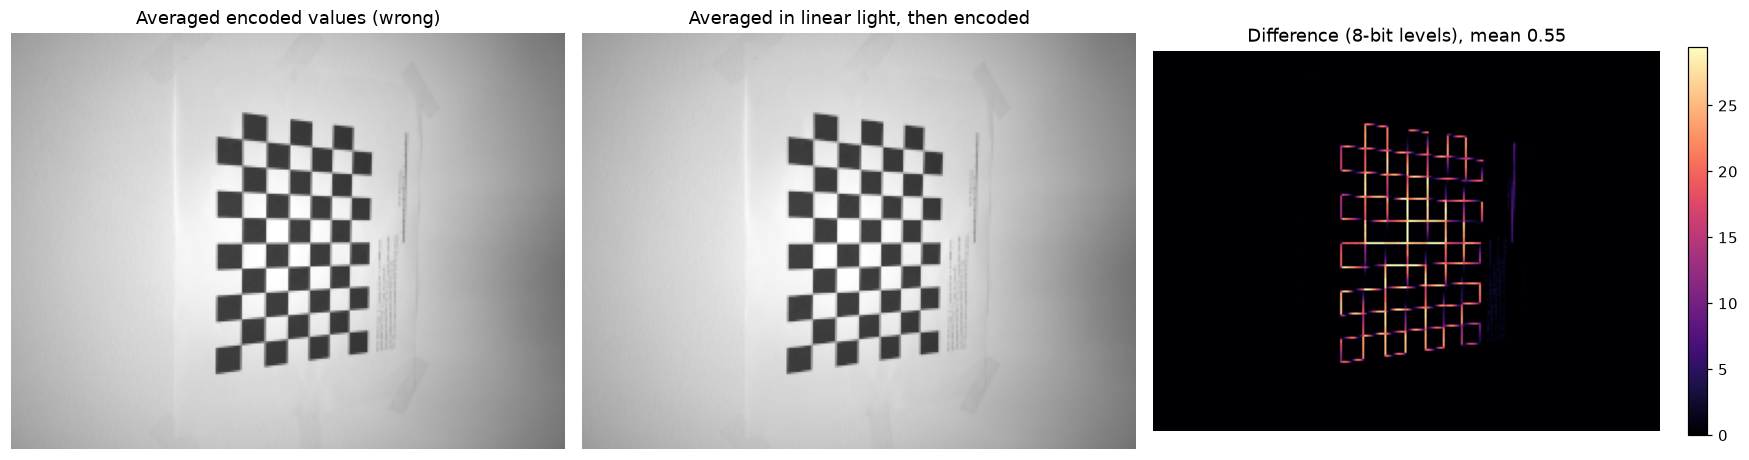

In [77]:
cal = sorted((A2_DIR / "calib_target_img").glob("*.dng"))

cal_file = cal[2]
g, info = green_plane(cal_file)
lin = np.clip((g - info["black"]) / (info["white"] - info["black"]), 0, None)
lin = np.clip(lin / np.percentile(lin, 99.5), 0, 1)            
enc = psu.linear_to_srgb(lin)

F = 8
H, W = (enc.shape[0] // F) * F, (enc.shape[1] // F) * F
def block_mean(x):
    return x[:H, :W].reshape(H // F, F, W // F, F).mean(axis=(1, 3))

small_enc = block_mean(enc)                                       
small_lin = psu.linear_to_srgb(block_mean(psu.srgb_to_linear(enc[:H, :W])))  
diff8 = (small_lin - small_enc) * 255
MAD8 = np.abs(diff8).mean()


print(f"Mean difference = {MAD8:.2f}")
edges = np.abs(diff8) > 2
print(f"Pixels with absdiff > 2 levels found in {100 * edges.mean():.1f} % of the image")

fig, axes = plt.subplots(1, 3, figsize=(16, 4.6))
axes[0].imshow(small_enc, cmap="gray", vmin=0, vmax=1); axes[0].set_title("Averaged encoded values (wrong)")
axes[1].imshow(small_lin, cmap="gray", vmin=0, vmax=1); axes[1].set_title("Averaged in linear light, then encoded")
im = axes[2].imshow(diff8, cmap="magma", vmin=0, vmax=np.percentile(diff8, 99.9))
axes[2].set_title(f"Difference (8-bit levels), mean {MAD8:.2f}")
fig.colorbar(im, ax=axes[2], fraction=0.035)
for ax in axes: ax.axis("off")
fig.tight_layout(); fig.savefig(OUT_DIR / "item13_downsample.png", bbox_inches="tight"); plt.show()

> **Answer**
> Mean absolute difference: 0.55. The error concentrates on the edges between black and white squares and high contrast spaces, where dark and bright can be mixed. Only 3.0 % of the reduced image differs by more than 2 levels.

# Part 6 Reflections

## Item 14 What did I learn?

Before the assignment I had no idea about the vendor tag and seems like a great way to compare concepts seen in courses to what actual vendors are using for their algorithms.
Additionally, I learned that the raw file images carry important information to understand more about image reconstruction and error.

## Item 15 Questions for the instructor

1. The gain rise in my data is expected for a phone camera, and based on this should we limit the fit to the linear region (low)?
2. Apple's Noiseprofile implies a higher readnoise is this to be conservative for denoising?
3. The long exposure and shortest exposure showed the same value when read using python. Why? 

Used AI for formatting on graphs and better understanding of values from calculations